# Lesson 6: Tree-Based Models

**Goals of this notebook:**
1. Move from the linear model (Logistic Regression) to **tree-based models**, which learn **feature combinations (interactions)** automatically,
   e.g. "short tenure **AND** fiber optic **AND** no tech support → high risk".
2. Go from simple to advanced: **Decision Tree → Random Forest → XGBoost**.
3. See **overfitting** with our own eyes, and how hyperparameters control it.
4. Compare tree **feature importance** with the Logistic Regression coefficients.
5. Add all new models to `data/model_results.csv` and compare them honestly.

# Setup

**Imports.**
- `DecisionTreeClassifier` and `plot_tree`: a single decision tree, and a function to draw it
- `RandomForestClassifier`: many trees that vote
- `XGBClassifier`: gradient-boosted trees from the `xgboost` library
- the same **metrics** functions as Lesson 5

Note: no `StandardScaler` this time (see the next cell for why).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay)

**Load the clean data and split it exactly like before.**
`random_state=42` and `stratify=y` give the **same train/test split** as Lessons 4 and 5, so all models are tested on the same 1,409 customers and the comparison is fair.

**Why no scaling?** A tree asks questions like *"Is tenure < 12?"*. It only cares whether a value is **above or below a cut-off**, not how big the numbers are.
Scaling tenure from 0–72 to −1.3…+1.6 would just move the cut-off; the tree would split the customers in exactly the same way.
(Logistic Regression needed scaling because it multiplies numbers by weights.)

Expected shapes: `(5634, 23) (1409, 23)`.

In [2]:
df = pd.read_csv("../data/telco_clean.csv")

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape, X_test.shape)

(5634, 23) (1409, 23)


**An evaluation helper function.**
We will evaluate three models in exactly the same way, so we write the code **once** in a function instead of copy-pasting it.
`evaluate(name, model)`:
1. predicts 0/1 (`predict`) and churn probabilities (`predict_proba`) on the test set
2. calculates the 5 metrics from Lesson 5 (accuracy, precision, recall, F1, ROC-AUC)
3. prints them and draws the confusion matrix
4. **returns** the scores as a dictionary, so we can collect them in `new_results` for the results table

In [3]:
def evaluate(name, model):
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    scores = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
    }

    for key, value in scores.items():
        if key != "Model":
            print(f"{key:9}: {value:.3f}")

    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
    plt.title(name)
    plt.show()

    return scores

new_results = []

# Part A: Decision Tree

**How a Decision Tree works: like the game "20 Questions".**
It is a chain of Yes/No questions, for example:
*"Is the contract Two year?"* → No → *"Is tenure < 12?"* → Yes → *"Is it Fiber optic?"* → Yes → **high churn risk**.

**The model chooses the questions by itself.** At every step it tries **every feature and every possible cut-off**, and picks the question that best separates churners from stayers.
"Best" is measured by **Gini impurity**:
- a **pure** group (all churners or all stayers) has Gini = 0 → good
- a **50/50 mix** has the highest Gini → bad

A path like "tenure < 12 **AND** fiber optic" is a **combination** of features, which Logistic Regression can't naturally learn (it just adds up separate effects).

**The overfitting trap: a tree with no limits.**
With no limits, the tree keeps asking questions until every leaf is perfectly pure, even if a leaf contains just **one** customer.
We compare accuracy on the **training** data (what it learned from) vs. the **test** data (unseen customers), and check how deep the tree grew.

In [4]:
tree_full = DecisionTreeClassifier(random_state=42)
tree_full.fit(X_train, y_train)

print("Train accuracy:", round(tree_full.score(X_train, y_train), 3))
print("Test accuracy :", round(tree_full.score(X_test, y_test), 3))
print("Tree depth    :", tree_full.get_depth())

Train accuracy: 0.998
Test accuracy : 0.726
Tree depth    : 23


**This is overfitting.** The tree is almost perfect on the training data but much worse on new customers.
Its test accuracy is even **worse than the lazy model (73.5%)** that just predicts "nobody churns".

**Student analogy:** a student who **memorizes last year's exam answers** scores 100% on last year's paper, but fails the real exam because the questions are different.
The tree memorized individual training customers (including noise and random quirks) instead of learning general patterns.

We do **not** add this unlimited tree to the results table; it's only here to show the problem.

**A controlled Decision Tree.**
We now set **hyperparameters**: choices **the human makes before training**. (The model still learns the questions by itself; we only set the rules of the game.)
- `max_depth=5`: ask at most 5 questions in a row, so the tree can't grow deep enough to memorize individuals
- `min_samples_leaf=20`: every final group (leaf) must contain at least 20 customers, so no rules are based on 1–2 people
- `class_weight="balanced"`: just like Lesson 5, mistakes on the rarer churners count ~3× more, to improve recall
- `random_state=42`: repeatable results

Then we compare train vs. test accuracy again, and evaluate with our helper (adding the scores to `new_results`).

Train accuracy: 0.734
Test accuracy : 0.73

Accuracy : 0.730
Precision: 0.495
Recall   : 0.807
F1       : 0.614
ROC-AUC  : 0.830


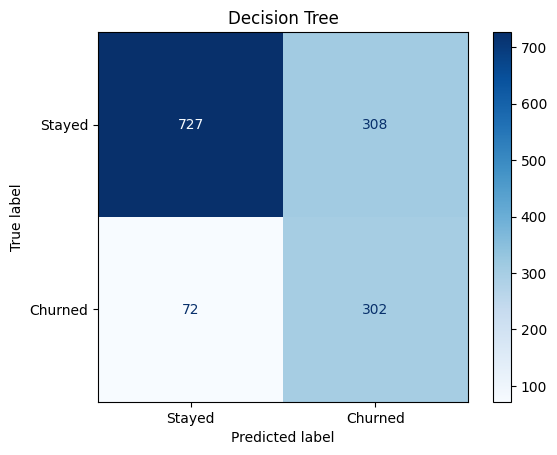

In [5]:
tree = DecisionTreeClassifier(max_depth=5,
                              min_samples_leaf=20,
                              class_weight="balanced",
                              random_state=42)
tree.fit(X_train, y_train)

print("Train accuracy:", round(tree.score(X_train, y_train), 3))
print("Test accuracy :", round(tree.score(X_test, y_test), 3))
print()
new_results.append(evaluate("Decision Tree", tree))

Now **train and test accuracy are close together**, so the tree is no longer memorizing. It learned general rules.
(Accuracy is lower than the unbalanced Logistic Regression because `class_weight="balanced"` trades accuracy for **recall**, exactly like in Lesson 5.)

**Draw the top of the tree.**
`max_depth=2` here **only limits the drawing** (the top 3 levels), not the model itself, which is still 5 levels deep. The full tree would be too big to read.

**How to read each box:**
- **first line**: the question, e.g. `Contract_Two year <= 0.5` means "is the contract NOT two-year?" (True → go left, False → go right)
- **gini**: how mixed the group is (0 = pure)
- **samples**: how many training customers reach this box
- **value**: the (weighted) amount of stayed vs. churned customers in the box
- **class**: the majority class, i.e. what the tree would predict here
- **colour**: orange-ish = mostly Stayed, blue-ish = mostly Churned; a stronger colour = a purer group

The **first split at the top is the most important question** the tree found.

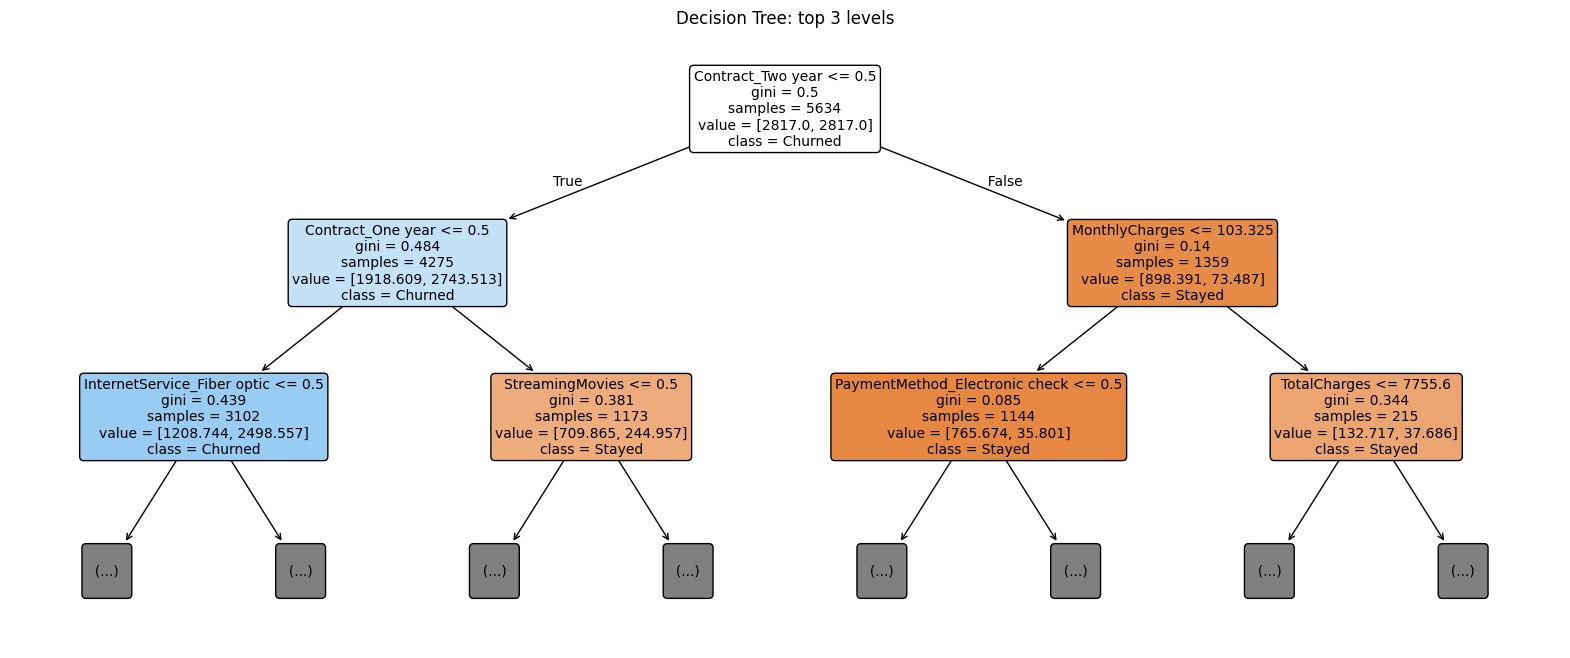

In [6]:
plt.figure(figsize=(20, 8))
plot_tree(tree, max_depth=2, feature_names=X.columns,
          class_names=["Stayed", "Churned"], filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree: top 3 levels")
plt.show()

The very first question is **"Is the contract Two year?"**, followed by **one-year contract** and **fiber optic**: the same top drivers we found in the EDA (Lesson 3).
(Tenure doesn't appear in the top 3 levels, but the tree uses it further down.)

**Why move on from one tree?**
- A single tree is **unstable**: a small change in the training data can produce a completely different tree.
- Its accuracy is **limited**: with only 5 questions per path, it can only draw fairly rough boundaries.

The fix: use **many** trees.

# Part B: Random Forest

**Wisdom of the crowd.** Ask 300 friends to guess how many sweets are in a jar. Each individual guess is off, but the **average** of all guesses is usually very close, because the errors cancel out.

A Random Forest does the same with trees:
- each tree is trained on a **random sample of customers** (drawn with replacement). This is called **bagging**.
- at every split, each tree may only look at a **random subset of the features**
- so the trees are all **different** and make **different mistakes**
- for a prediction, all the trees **vote**, and the mistakes cancel out → more accurate and much more stable than one tree

**Train the Random Forest.**
- `n_estimators=300`: build 300 trees
- `max_depth=10`: each tree can ask up to 10 questions (deeper than our single tree, because averaging protects against overfitting)
- `min_samples_leaf=5`: each leaf needs at least 5 customers
- `class_weight="balanced"`: give churners more weight, to improve recall
- `random_state=42`: repeatable results
- `n_jobs=-1`: use **all CPU cores** to train trees in parallel (faster)

Train accuracy: 0.824
Test accuracy : 0.762

Accuracy : 0.762
Precision: 0.536
Recall   : 0.759
F1       : 0.628
ROC-AUC  : 0.845


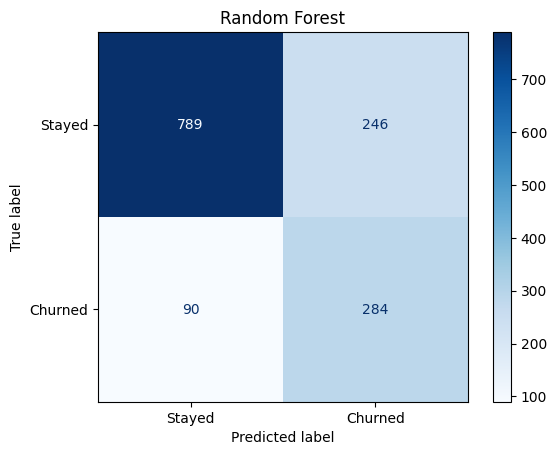

In [7]:
rf = RandomForestClassifier(n_estimators=300,
                            max_depth=10,
                            min_samples_leaf=5,
                            class_weight="balanced",
                            random_state=42,
                            n_jobs=-1)
rf.fit(X_train, y_train)

print("Train accuracy:", round(rf.score(X_train, y_train), 3))
print("Test accuracy :", round(rf.score(X_test, y_test), 3))
print()
new_results.append(evaluate("Random Forest", rf))

**Feature importance: which features did the forest use most?**
`rf.feature_importances_` measures how much each feature **reduced Gini impurity** across all splits in all 300 trees. The values add up to 1.

**Difference from the Logistic Regression coefficients (Lesson 5):**
- LR coefficients have a **direction**: + increases churn, − decreases churn.
- Tree importance is **always positive** and shows only **how much** a feature matters, **not the direction**.
  For example, "tenure is important" doesn't tell us whether long tenure raises or lowers churn.

(**SHAP**, in the next lesson, will give us both the size *and* the direction.)

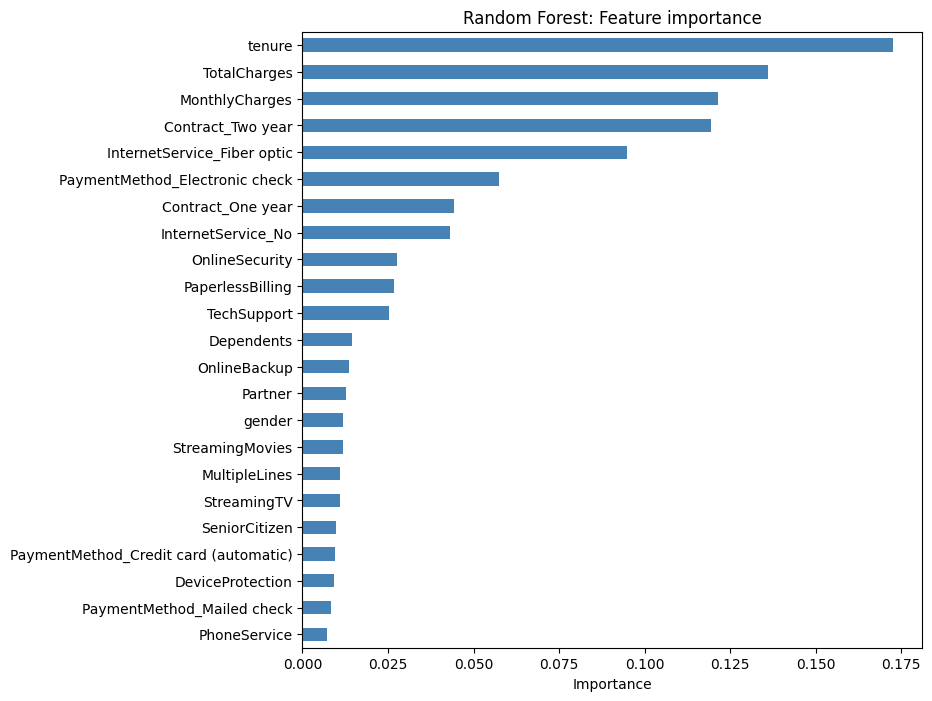

In [8]:
rf_importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 8))
rf_importance.plot(kind="barh", color="steelblue")
plt.title("Random Forest: Feature importance")
plt.xlabel("Importance")
plt.show()

**Top 5 Random Forest features** as numbers.

In [9]:
print(rf_importance.sort_values(ascending=False).head(5).round(3))

tenure                         0.173
TotalCharges                   0.136
MonthlyCharges                 0.122
Contract_Two year              0.119
InternetService_Fiber optic    0.095
dtype: float64


# Part C: XGBoost

**Boosting = learning from mistakes.**
- Random Forest builds its trees **independently** (all at the same time) and lets them vote.
- XGBoost builds trees **one after another**. Each new tree focuses on the **errors of the previous trees** and tries to correct them.
  The final prediction adds up the (small) contributions of all trees.

**Student analogy:** after each mock test, the student studies **only the questions they got wrong**. Test after test, the weak spots get fixed.

XGBoost is one of the most widely used models in industry and on Kaggle for **tabular data** (tables like ours).

**How imbalanced is the training data?**
We divide the number of stayers by the number of churners in the training set. Expected: **~2.77**, so there are ~2.77 stayers for every churner.

XGBoost doesn't use `class_weight`. Instead it has `scale_pos_weight`, which multiplies the weight of the **positive class (churn = 1)**.
The standard value is exactly this ratio, which has the same effect as `class_weight="balanced"`.

In [10]:
ratio = (y_train == 0).sum() / (y_train == 1).sum()
print("Stayed / Churned ratio:", round(ratio, 2))

Stayed / Churned ratio: 2.77


**Train XGBoost.** Every parameter explained:

| Parameter | Value | Meaning |
|---|---|---|
| `n_estimators` | 300 | build 300 trees, one after another |
| `learning_rate` | 0.05 | how much each new tree is allowed to correct: **small, careful steps** (a small value needs more trees but generalizes better) |
| `max_depth` | 4 | each tree is small (max 4 questions); boosting works best with many **weak, shallow** trees |
| `subsample` | 0.8 | each tree sees a random 80% of the customers (adds randomness → less overfitting) |
| `colsample_bytree` | 0.8 | each tree sees a random 80% of the features (same idea) |
| `scale_pos_weight` | ratio (~2.77) | give churners ~2.77× more weight, to handle imbalance |
| `eval_metric` | "logloss" | the error measure XGBoost tracks during training (same log loss as Logistic Regression) |
| `random_state` | 42 | repeatable results |

Train accuracy: 0.81
Test accuracy : 0.752

Accuracy : 0.752
Precision: 0.522
Recall   : 0.783
F1       : 0.627
ROC-AUC  : 0.840


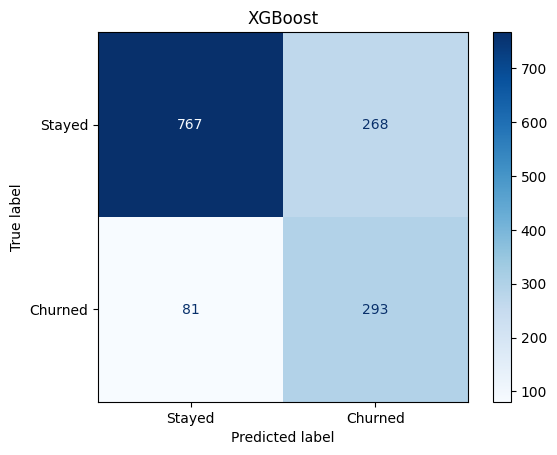

In [11]:
xgb = XGBClassifier(n_estimators=300,
                    learning_rate=0.05,
                    max_depth=4,
                    subsample=0.8,
                    colsample_bytree=0.8,
                    scale_pos_weight=ratio,
                    eval_metric="logloss",
                    random_state=42)
xgb.fit(X_train, y_train)

print("Train accuracy:", round(xgb.score(X_train, y_train), 3))
print("Test accuracy :", round(xgb.score(X_test, y_test), 3))
print()
new_results.append(evaluate("XGBoost", xgb))

**XGBoost feature importance.**
Same idea as for the Random Forest: how much each feature contributed, with **no direction**.
(By default XGBoost measures importance by "gain", meaning how much the splits on that feature improved the model.)

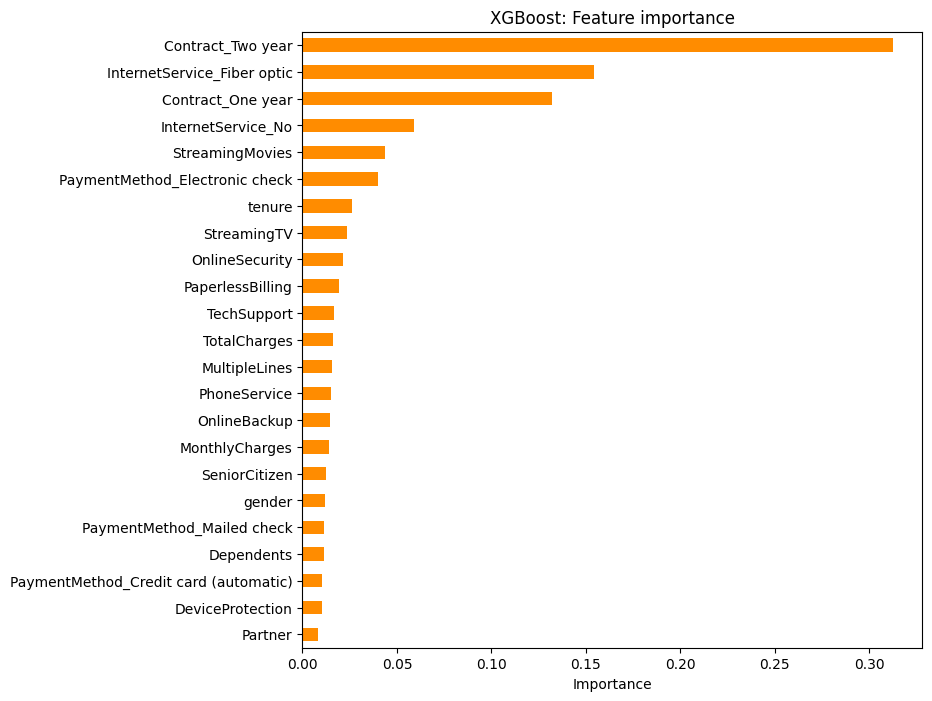

In [12]:
xgb_importance = pd.Series(xgb.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(8, 8))
xgb_importance.plot(kind="barh", color="darkorange")
plt.title("XGBoost: Feature importance")
plt.xlabel("Importance")
plt.show()

**Top 5 XGBoost features** as numbers.

In [13]:
print(xgb_importance.sort_values(ascending=False).head(5).round(3))

Contract_Two year              0.312
InternetService_Fiber optic    0.154
Contract_One year              0.132
InternetService_No             0.059
StreamingMovies                0.044
dtype: float32


**Why do Random Forest and XGBoost rank features differently?** Each model measures importance in its own way:
- **Random Forest** (impurity-based importance) tends to favour **numeric** columns like tenure and charges, because they offer many possible cut-offs and get used in many splits.
- **XGBoost** ("gain") rewards the features that give the **biggest improvement per split**. The strong Yes/No columns, like Contract_Two year and Fiber optic, separate churners in one clean question, so they get most of the credit.

So the exact ranking differs, but the **same core drivers keep appearing**: **contract** and **fiber optic** are near the top for every model, and tenure, charges, payment method (electronic check) and the support/streaming services also show up. These match the Logistic Regression coefficients and the EDA.

When **several different models agree** (and they also agree with the EDA), the finding is much more **trustworthy**.

# Part D: Compare all models

**Add the new models to the results table.**
1. Load the existing table from Lesson 5 (Lazy, Logistic Regression, Logistic Regression (balanced)).
2. **Remove any old rows for the three tree models** first. If we run this notebook a second time, the table already contains them; without this step we would get **duplicate rows**.
   `isin([...])` finds rows whose Model is in the list, and `~` means "NOT", so we keep every row that is *not* a tree model.
3. Add the 3 new rows from `new_results`, round to 3 decimals, and save.

Expected: **6 rows**.

In [14]:
old_results = pd.read_csv("../data/model_results.csv")
old_results = old_results[~old_results["Model"].isin(["Decision Tree", "Random Forest", "XGBoost"])]

all_results = pd.concat([old_results, pd.DataFrame(new_results)], ignore_index=True).round(3)

all_results.to_csv("../data/model_results.csv", index=False)
all_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Lazy (predict all stay),0.735,0.000,0.000,0.000,0.500
1,Logistic Regression,0.806,0.658,0.556,0.603,0.842
2,Logistic Regression (balanced),0.740,0.507,0.786,0.616,0.842
3,Decision Tree,0.730,0.495,0.807,0.614,0.830
4,Random Forest,0.762,0.536,0.759,0.628,0.845
5,XGBoost,0.752,0.522,0.783,0.627,0.840


**Comparison chart** of the metrics that matter most for churn: **Recall**, **ROC-AUC** and **F1**.
We leave out the lazy model (its scores are 0 and would only clutter the chart).

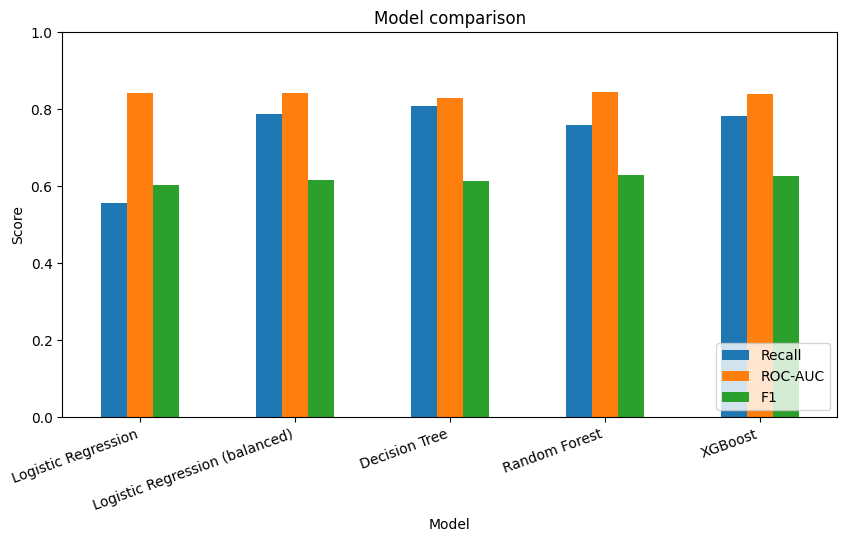

In [15]:
compare = all_results[all_results["Model"] != "Lazy (predict all stay)"]

compare.set_index("Model")[["Recall", "ROC-AUC", "F1"]].plot(kind="bar", figsize=(10, 5))
plt.title("Model comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=20, ha="right")
plt.legend(loc="lower right")
plt.show()

**Best ROC-AUC, and how far it is above balanced Logistic Regression.**

In [16]:
best = all_results.sort_values("ROC-AUC", ascending=False).iloc[0]
lr_bal_auc = all_results.loc[all_results["Model"] == "Logistic Regression (balanced)", "ROC-AUC"].values[0]

print("Best ROC-AUC model:", best["Model"], "→", best["ROC-AUC"])
print("Logistic Regression (balanced) →", lr_bal_auc)
print("Difference:", round(best["ROC-AUC"] - lr_bal_auc, 3))

Best ROC-AUC model: Random Forest → 0.845
Logistic Regression (balanced) → 0.842
Difference: 0.003


## Honest result
The tree models are only **slightly better** than balanced Logistic Regression, or about equal. The best one (Random Forest, ROC-AUC 0.845) is just **0.003** above LR (balanced, 0.842), and XGBoost (0.840) is even slightly below it with these hand-picked settings.

This is a **real finding, not a failure**. The Telco data's signal comes mostly from a **few strong features** (contract, tenure, internet type, charges) that a linear model already captures well, so there aren't many complex interactions left for the trees to discover.
In practice, when performance is similar, a **simpler model is often preferred** because it is easier to explain to the business.

## Findings (Lesson 6)
1. An **unlimited Decision Tree overfits**: ~99% train vs. ~73% test accuracy (it memorized the data). Limiting depth and leaf size fixed this.
2. Trees **don't need scaling**, because they split on thresholds.
3. **Random Forest** (300 trees voting, bagging) is more stable than a single tree.
4. **XGBoost** (boosting: each tree fixes the previous mistakes) reached ROC-AUC 0.840 with recall 0.783. **Random Forest had the best ROC-AUC (0.845)** and the best F1 (0.628).
5. Imbalance was handled with `class_weight="balanced"` (Tree, RF) and `scale_pos_weight ≈ 2.77` (XGBoost).
6. All models agree on the main churn drivers: contract and fiber optic at the top, plus tenure, charges, payment method and support services (the exact ranking depends on how each model measures importance).
7. Tree models were only **slightly better** than balanced Logistic Regression, or about equal: Random Forest 0.845 vs. LR (balanced) 0.842 ROC-AUC (+0.003), and XGBoost 0.840 was even slightly below. The dataset is fairly simple, so the interpretable model remains a strong option.

## Why move on (Lesson 6B)
1. Hyperparameters were chosen **by hand**. We should search for better ones properly using **cross-validation** (a more reliable test than one single train/test split).
2. Tree feature importance has **no direction** and doesn't explain **individual customers**. **SHAP** answers "how does each feature push risk up or down?" and "why is *this* customer at 85% risk?", which the business needs in order to act.